# Population Size and History from Present-Day DNA

Can DNA sampled today distinguish a founder event from recent growth?
We generate one population with mutation, recombination and changing size.
The simulator records each generation. Estimators receive the final DNA,
an external mutation rate and a genetic map.

Diversity, LD and IBD give constant-size summaries. We compare specified
demographic histories and check their predictions on reserved chromosomes.
The simulation uses small population sizes and elevated rates so that its
probability model can be inspected directly. Install hpgR before running.


In [1]:
library(hpgR)
options(repr.plot.width = 9, repr.plot.height = 3.8,
        repr.plot.pointsize = 16, repr.plot.bg = "white", warn = 1)
blue <- "#0072B2"
orange <- "#D65F22"
gray <- "#777777"
truth_color <- "#D62728"
model_colors <- c(expansion_only = "#0072B2", shallow_founding = "#009E73",
    recent_founding = "#D62728", older_founding = "#A84CAB")

drawFigure <- function(name, draw, width = 9, height = 3.8, pointsize = 16) {
    options(repr.plot.width = width, repr.plot.height = height,
            repr.plot.pointsize = pointsize)
    directory <- Sys.getenv("P8149_FIGURE_DIR")
    if (nzchar(directory)) {
        dir.create(directory, recursive = TRUE, showWarnings = FALSE)
        pdf(file.path(directory, paste0(name, ".pdf")), width = width,
            height = height, family = "Helvetica", pointsize = pointsize,
            useDingbats = FALSE, bg = "white")
        tryCatch({layout(1); draw()}, finally = dev.off())
    }
    if ("IRkernel" %in% loadedNamespaces()) {layout(1); draw()}
    invisible(NULL)
}


## The final sample and its calibration

The embedded data contain **64 diploid people**, represented by **128 haploid
sequences**, across **eight chromosomes of 10,000 sites each**. Every site,
including invariant sites, is included. Consecutive haplotype rows are the
two homologs of one person. Alleles are coded 0 and 1.

Each chromosome spans 0.2 Morgans. The mutation probability is
$u=v=2.5\times10^{-5}$ per site per generation for both 0-to-1 and 1-to-0
changes. Recurrent and reverse mutation are possible, so the frequency
spectrum uses **minor allele counts**. Allele 1 is simply a sequence state.

`observed` contains the final DNA. `calibration` contains the mutation rate
and map. `prediction_data` contains independent R simulation predictions
for candidate histories. It contains no generation records from the observed sample.


In [2]:
observed <- (function() {
  encoded <- c(
    "..."
  )
  payload <- memDecompress(base64enc::base64decode(paste0(encoded, collapse = "")), "gzip")
  con <- rawConnection(payload)
  on.exit(close(con))
  readRDS(con)
})()

calibration <- (function() {
  encoded <- c(
    "..."
  )
  payload <- memDecompress(base64enc::base64decode(paste0(encoded, collapse = "")), "gzip")
  con <- rawConnection(payload)
  on.exit(close(con))
  readRDS(con)
})()

prediction_data <- (function() {
  encoded <- c(
    "..."
  )
  payload <- memDecompress(base64enc::base64decode(paste0(encoded, collapse = "")), "gzip")
  con <- rawConnection(payload)
  on.exit(close(con))
  readRDS(con)
})()


## Run the forward model

Begin with 100 diploid individuals carrying allele 0 at every site.
Mutation and reproduction run for 1,000 ancestral generations before the
founder sample is taken. This **burn-in** lets diversity build and fluctuate
near its mutation-drift equilibrium.

Then sample 20 founders, keep the population at 20 for 20 generations,
and expand exponentially to 1,000 over 40 generations. Every generation
uses the R-translated simuPOP operators in the same order.

1. Each parental allele flips with probability $u=v$.
2. Each gamete chooses a parental diploid uniformly, with replacement.
3. The gamete switches between that parent's homologs at the supplied
   recombination fractions. Different chromosomes assort independently.
4. Two gametes form each offspring. Selfing is allowed in this neutral
   Wright-Fisher model.

For adjacent sites separated by $d$ Morgans, the switch probability is
$r=(1-e^{-2d})/2$. `hpgR` implements mutation and transmission in R;
the notebook specifies the demographic schedule.

At one site, the copying step has the marginal probability model
$K_{\ell,g+1}\mid\widetilde p_{\ell,g}\sim
\operatorname{Binomial}(2N_{g+1},\widetilde p_{\ell,g})$, where
$\widetilde p_{\ell,g}$ is the frequency after parental mutation.
Recombination determines which neighboring sites travel in the same gamete.


In [3]:
population_design <- prediction_data$design
candidate_designs <- prediction_data$candidates
candidate_labels <- prediction_data$labels

simulation <- simulatePopulationHistory(candidate_designs$recent_founding, population_design,
    seed = population_design$observation_seed, recordEvery = 1L)
stopifnot(identical(simulation$observed, observed),
          identical(simulation$calibration, calibration))
cat("The R simulation reproduced the supplied final sample.\n")


The R simulation reproduced the supplied final sample.


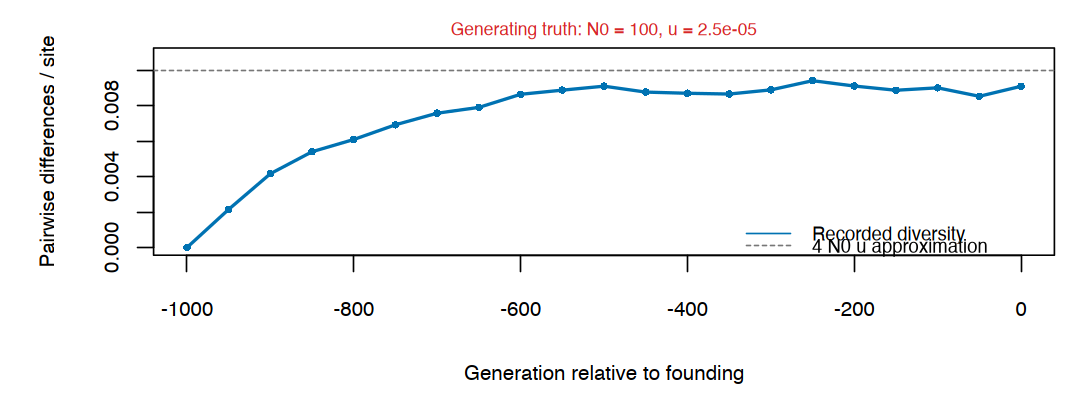

In [4]:
if (!is.null(simulation)) {
    drawFigure("population_burnin", function() {
        burn <- simulation$records$burnin
        H <- burn$heterozygosity * 2 * burn$size / (2 * burn$size - 1)
        par(mar = c(4.4, 4.8, 1.5, .8), bg = "white")
        plot(burn$generation, H, type = "o", pch = 16, cex = .55,
             col = blue, lwd = 2, xlab = "Generation relative to founding",
             ylab = "Pairwise differences / site", ylim = c(0, max(H) * 1.15))
        abline(h = 4 * population_design$ancestral_size *
            calibration$mutationRate, lty = 2, col = gray)
        legend("bottomright", c("Recorded diversity", "4 N0 u approximation"),
               lty = c(1, 2), col = c(blue, gray), bty = "n", cex = .9,
               y.intersp = 1.8)
        mtext(sprintf("Generating truth: N0 = %d, u = %.2g",
            population_design$ancestral_size, calibration$mutationRate),
            side = 3, line = .3, col = truth_color, cex = .85)
    }, height = 3.3)
}


The dashed line marks the low-mutation approximation $4N_0u=0.01$.
The next plots show population records for this realization. Founder sampling
can change frequencies immediately; new mutations add variation during growth.
The two values at generation 0 show the population before and after the
instantaneous founder sample.


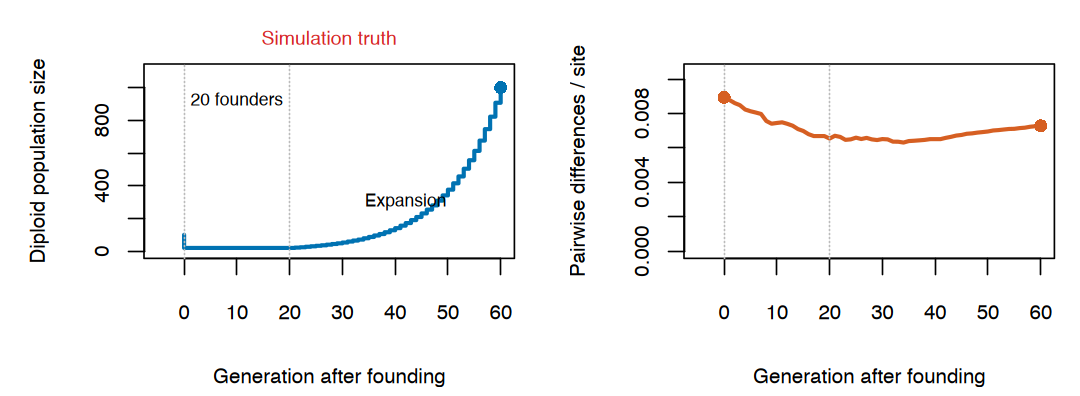

In [5]:
if (!is.null(simulation)) {
    drawFigure("population_demography", function() {
        record <- simulation$records$generation
        H <- record$heterozygosity * 2 * record$size / (2 * record$size - 1)
        ancestral <- tail(simulation$records$burnin, 1L)
        initial_H <- ancestral$heterozygosity * 2 * ancestral$size /
            (2 * ancestral$size - 1)
        time <- c(0, record$generation)
        par(mfrow = c(1, 2), mar = c(4.3, 4.5, 2, .8), bg = "white")
        plot(time, c(population_design$ancestral_size, record$size),
             type = "s", lwd = 2.5, xlim = c(-5, 60),
             col = blue, xlab = "Generation after founding",
             ylab = "Diploid population size", ylim = c(0, 1100))
        abline(v = c(0, 20), col = "#BBBBBB", lty = 3)
        mtext("Simulation truth", side = 3, line = .5,
              col = truth_color, cex = .95)
        text(10, 930, "20 founders", cex = .85)
        text(42, 300, "Expansion", cex = .85)
        points(60, 1000, pch = 16, col = blue)
        plot(time, c(initial_H, H), type = "l", col = orange, xlim = c(-5, 60),
             lwd = 2.5, xlab = "Generation after founding",
             ylab = "Pairwise differences / site",
             ylim = c(0, max(c(H, initial_H)) * 1.15))
        abline(v = c(0, 20), col = "#BBBBBB", lty = 3)
        points(record$generation[c(1, nrow(record))], H[c(1, length(H))],
               pch = 16, col = orange)
    }, height = 3.3)
}


## Analyze only the final DNA

From here onward the estimation functions use `observed`, `calibration`
and the candidate prediction banks. They do not receive `simulation`,
parental identities, recorded frequencies or the generating sizes.

The matrix displays the first 12 haplotypes at 12 common polymorphic sites
on chromosome 1. Labels give physical positions in bases. The complete
analysis uses all 80,000 sites and all 128 haplotypes.


 diploid_people haplotypes analyzed_sites segregating_sites pairwise_diversity
             64        128          80000              5152          0.0073229


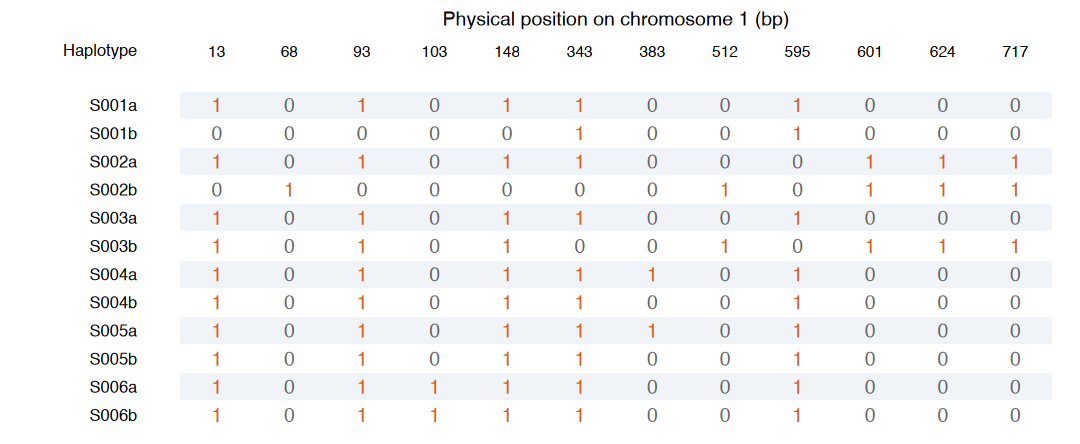

In [6]:
dna_summary <- summarizePopulationSample(observed$haplotypes,
    chromosome = observed$markers$chromosome)
print(data.frame(diploid_people = nrow(observed$genotypes),
    haplotypes = dna_summary$nHaplotypes, analyzed_sites = dna_summary$sequenceLength,
    segregating_sites = dna_summary$segregatingSites,
    pairwise_diversity = dna_summary$piPerSite), row.names = FALSE, digits = 5)

drawFigure("population_final_dna", function() {
    H <- observed$haplotypes
    frequency <- colMeans(H)
    sites <- which(observed$markers$chromosome == 1L &
                   pmin(frequency, 1 - frequency) >= .1)[1:12]
    subset <- H[1:12, sites, drop = FALSE]
    labels <- paste0(rep(observed$sample_ids[1:6], each = 2L), c("a", "b"))
    par(mar = c(.2, .2, .2, .2), bg = "white")
    plot(NA, xlim = c(-1.9, 12.8), ylim = c(-.8, 14.5),
         axes = FALSE, xlab = "", ylab = "", xaxs = "i", yaxs = "i")
    text(6.5, 14.0, "Physical position on chromosome 1 (bp)", cex = .95)
    text(1:12, 12.9, observed$markers$position[sites], cex = .75)
    text(-.1, 12.9, "Haplotype", adj = 1, cex = .8)
    for (i in 1:12) {
        y <- 12 - i
        rect(.5, y - .46, 12.5, y + .46,
             col = if (i %% 2L) "#F0F4F8" else "white", border = NA)
        text(-.1, y, labels[i], adj = 1, cex = .8)
        text(1:12, rep(y, 12), subset[i, ],
             col = ifelse(subset[i, ] == 1L, orange, "#666666"), cex = .95)
    }
}, height = 3.7)


Diversity counts differences between pairs of sequences. The folded SFS
counts sites at each minor allele count, from 1 through 64 among 128 copies.
The chromosomes differ because they have different realized copying and
recombination histories. They remain parts of the same sampled population.


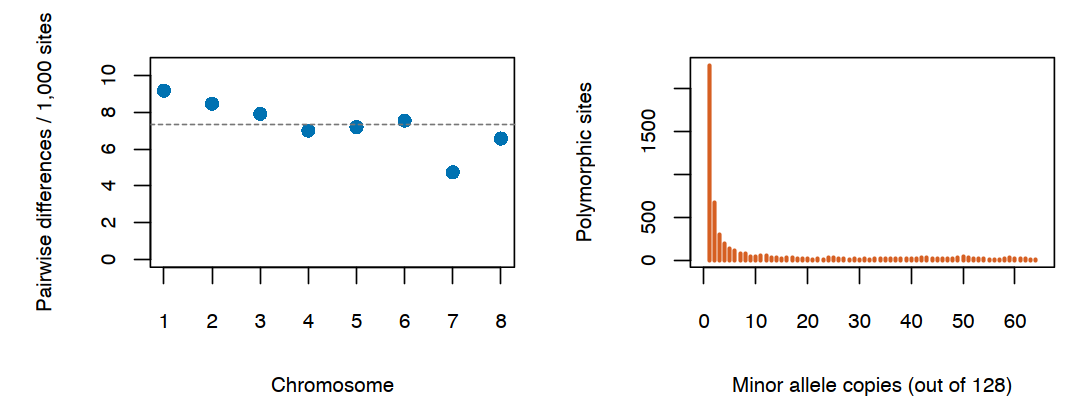

In [7]:
drawFigure("population_sample_summaries", function() {
    by_chr <- dna_summary$byChromosome
    H <- vapply(by_chr, `[[`, numeric(1), "piPerSite")
    par(mfrow = c(1, 2), mar = c(4.4, 4.7, 1.8, .8), bg = "white")
    plot(seq_along(H), 1000 * H, pch = 16, col = blue, cex = 1.1,
         xaxt = "n", xlab = "Chromosome", ylab = "Pairwise differences / 1,000 sites",
         ylim = c(0, max(H) * 1150))
    axis(1, seq_along(H), names(H))
    abline(h = 1000 * dna_summary$piPerSite, lty = 2, col = gray)
    plot(seq_along(dna_summary$foldedSfs), dna_summary$foldedSfs,
         type = "h", lwd = 2.5, col = orange,
         xlab = "Minor allele copies (out of 128)",
         ylab = "Polymorphic sites", xlim = c(0, 65))
}, height = 3.4)


## Estimate effective size using diversity and mutation rate

Apply the mutation-drift relation from Lecture 8 to the final DNA.
If $k_\ell$ of the $n=128$ sampled copies carry allele 1, then

$$\widehat H=\frac{1}{L}\sum_\ell
\frac{2k_\ell(n-k_\ell)}{n(n-1)},\qquad
\widehat N_{e,H}=\frac{\widehat H}{4u}.$$

Here $L=80{,}000$ includes invariant sites. The inverse assumes a neutral,
constant-size population and rare mutation. With changing population size,
it summarizes accumulated ancestral time; it need not equal today's census.


In [8]:
diversity_fit <- estimateDiversitySize(observed$haplotypes,
    mutationRate = calibration$mutationRate,
    sequenceLength = calibration$sequenceLength)
finite_state_fit <- estimateDiversitySize(observed$haplotypes,
    mutationRate = calibration$mutationRate,
    sequenceLength = calibration$sequenceLength,
    mutationModel = "symmetric_parental")
print(data.frame(pairwise_diversity = diversity_fit$piPerSite,
    mutation_rate = diversity_fit$mutationRate,
    Ne_rare_mutation = diversity_fit$Ne,
    Ne_symmetric_mutation = finite_state_fit$Ne), row.names = FALSE, digits = 6)


 pairwise_diversity mutation_rate Ne_rare_mutation Ne_symmetric_mutation
         0.00732294       2.5e-05          73.2294               74.8197


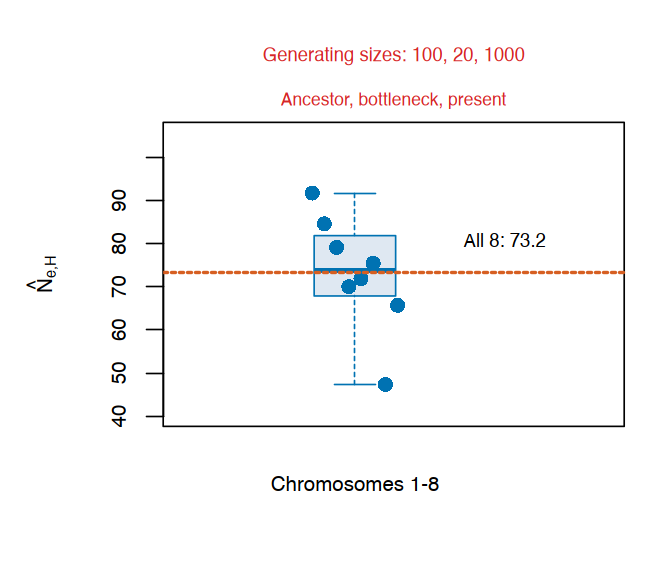

In [9]:
chromosome_sizes <- vapply(dna_summary$byChromosome,
    function(x) x$piPerSite / (4 * calibration$mutationRate), numeric(1))
drawFigure("population_diversity_estimates", function() {
    par(mar = c(4.4, 4.8, 3.6, .7), bg = "white")
    boxplot(chromosome_sizes, at = 1, boxwex = .42,
        xlim = c(.55, 1.65), ylim = range(chromosome_sizes) * c(.85, 1.15),
        col = "#DFE8F2", border = blue, outline = FALSE, xaxt = "n",
        ylab = expression(hat(N)[e*","*H]), xlab = "")
    points(seq(.89, 1.11, length.out = length(chromosome_sizes)),
           chromosome_sizes, pch = 16, col = blue, cex = 1.1)
    axis(1, 1, "Chromosomes 1-8", tick = FALSE)
    abline(h = diversity_fit$Ne, col = orange, lty = 2, lwd = 2)
    text(1.28, diversity_fit$Ne + 6,
        sprintf("All 8: %.1f", diversity_fit$Ne), adj = c(0, 0), cex = .9)
    mtext(sprintf("Generating sizes: %d, %d, %d",
        population_design$ancestral_size,
        candidate_designs$recent_founding$small,
        population_design$present_size), side = 3, line = 1.7,
        col = truth_color, cex = .9)
    mtext("Ancestor, bottleneck, present", side = 3, line = .4,
          col = truth_color, cex = .85)
}, width = 5.4, height = 4.8, pointsize = 17)


The symmetric-mutation correction gives 74.8, compared with
73.2 from the rare-mutation relation. Both invert constant-size equilibrium
models. Population size changed during this example.

The box and points show chromosome-specific estimates within this one sample.
They show regional variation; they are not independent population replicates
or a confidence interval for the pooled estimate. Red labels give the generating
sizes, which are withheld from estimation.


## Estimate effective size using LD and recombination

Use one fixed chromosome copy from each of the same 64 people, giving
$n=64$ known-phase haplotypes. At sites $A,B$, let $X_A,X_B\in\{0,1\}$
indicate allele 1 on the same haplotype. Their correlation is
$\rho_{AB}=\operatorname{Corr}(X_A,X_B)$; its square measures LD.

The neutral constant-size, weak-LD model from Lecture 8 separates population
LD from the additional contribution of study sampling:

$$E\!\left(\widehat{\rho_{AB}^{\,2}}\right)
\approx\frac{\gamma(r)}{N_e}+\frac{1}{n},\qquad
\gamma(r)=\frac{(1-r)^2+r^2}{2r(2-r)}.$$

Finite sampling makes the observed squared correlation positive on average
even when the population correlation is zero. Here the approximate sampling
contribution is $1/64=0.015625$. Subtract it before estimating effective size:

$$\widehat m=\overline{\widehat{\rho_{AB}^{\,2}}}-\frac{1}{n},\qquad
\widehat N_{e,\mathrm{LD}}\approx\frac{\overline{\gamma(r)}}{\widehat m}.$$

$\widehat m$ estimates mean population squared LD. Bars average over the
same selected SNP pairs, whose recombination fractions can differ.

Each simulated chromosome spans 0.20 Morgans. We choose a lower pair-distance
cutoff of 0.03 Morgans to exclude the tightest pairs, where strong LD can make
the approximation inaccurate. These are pairwise separations of 3–20 cM.
Require sample minor-allele frequency at least 0.10 to reduce rare-allele bias.
For Poisson crossovers, the map converts pair distance $d$ to the recombination
fraction $r=(1-e^{-2d})/2$.

The sample correction is approximate for this finite, paired-diploid
population sample. Population simulations below use the same sampling design
when calibrating predictions.


 lowerMorgan upperMorgan pairs  meanRho2 correctedRho2      Ne
        0.03        0.07 19111 0.0384455    0.02282047 232.198
        0.07        0.12 16267 0.0203700    0.00474498 560.981
        0.12        0.20 10085 0.0189476    0.00332265 501.337


Pooled LD estimate: 295.1 


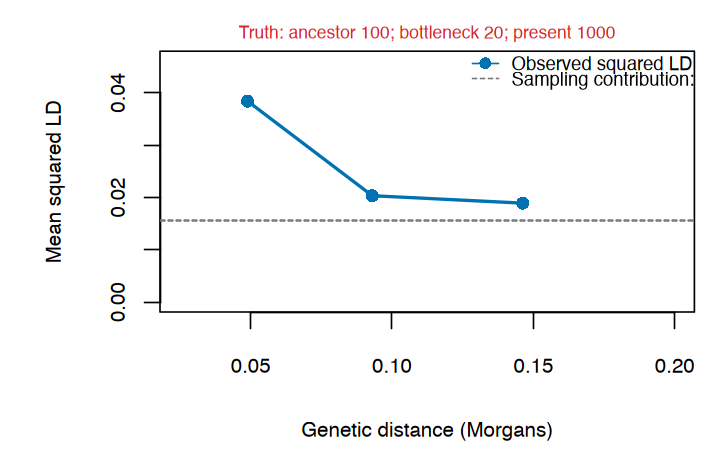

In [10]:
ld_haplotypes <- observed$haplotypes[
    seq(1L, nrow(observed$haplotypes), 2L), , drop = FALSE]
ld_fit <- estimateLdSize(ld_haplotypes,
    geneticPositions = observed$markers$genetic_position,
    chromosome = observed$markers$chromosome,
    distanceBreaks = population_design$ld_distance_breaks,
    maxPairs = 500000L, seed = 101L)
print(ld_fit$bins[c("lowerMorgan", "upperMorgan", "pairs", "meanRho2",
                   "correctedRho2", "Ne")], row.names = FALSE, digits = 6)
cat("Pooled LD estimate:", round(ld_fit$Ne, 2), "\n")

drawFigure("population_ld_estimates", function() {
    bins <- ld_fit$bins
    par(mar = c(4.5, 5, 1.6, .8), bg = "white")
    plot(bins$meanDistance, bins$meanRho2, type = "o", pch = 16,
         col = blue, lwd = 2, xlim = c(.025, .2),
         ylim = c(0, max(bins$meanRho2) * 1.2),
         xlab = "Genetic distance (Morgans)",
         ylab = "Mean squared LD")
    abline(h = ld_fit$samplingCorrection, lty = 2, col = gray, lwd = 1.5)
    legend("topright", c("Observed squared LD", "Sampling contribution: 1/64"),
           col = c(blue, gray), lty = c(1, 2), pch = c(16, NA),
           bty = "n", cex = .9, y.intersp = 1.8)
    mtext(sprintf("Truth: ancestor %d; bottleneck %d; present %d",
        population_design$ancestral_size,
        candidate_designs$recent_founding$small, population_design$present_size),
          side = 3, line = .3, col = truth_color, cex = .85)
}, width = 6, height = 3.8, pointsize = 16)


The 45,463 selected within-chromosome SNP pairs give

$$\widehat N_{e,\mathrm{LD}}\approx
\frac{\overline{\gamma(r)}}{\overline{\widehat{\rho_{AB}^{\,2}}}-1/64}
=\frac{3.54939}{0.0276527-1/64}
\approx295.$$

The function samples at most 500,000 candidate SNP pairs before restricting
them to the same chromosome and the chosen distance range.
Each selected pair contributes once to both means. Bin-specific inverses apply the
same approximation to different distances. They are not estimates for distinct
historical epochs. Linked pairs share sites and chromosomes.


## Estimate effective size using IBD lengths

Use the same fixed haplotype from each of 64 people. Match common markers
(minor-allele frequency at least 0.10), and analyze matches at least 8 cM long.
The expanded marker panel reduces chance long matches. Phase is known and the
simulation has no genotyping error.

For bin $b$, sum matching segment lengths and divide by the total analyzed
map length $G=160$ cM and the number of compared haplotype pairs $P=\binom{64}{2}$:

$$\widehat f_b=\frac{\sum_{s:\,\ell_s\in b}\ell_s}{P G}.$$

As previously discussed, predict these fractions from inheritance and recombination.
Here we restrict that model to a constant size $N$:

$$\widehat N_{e,\mathrm{IBD}}=\arg\min_N\sum_b
 [\log\widehat f_b-\log f_b(N)]^2.$$

`expectedIbdLength()` translates the finite-chromosome expectation from
Dan Nachun's demographyTools. `estimateIbdSize()` uses the positive-bin
criterion described by [Carmi et al. (2014)](https://www.nature.com/articles/ncomms5835).
It fits a constant-size summary, rather than a free size trajectory.


 lowerCm upperCm count sharedCm    fraction
       8      10   543 4849.081 0.015033113
      10      14   297 3344.362 0.010368187
      14     Inf    97 1635.964 0.005071812


Constant-size IBD fit: 164.1 


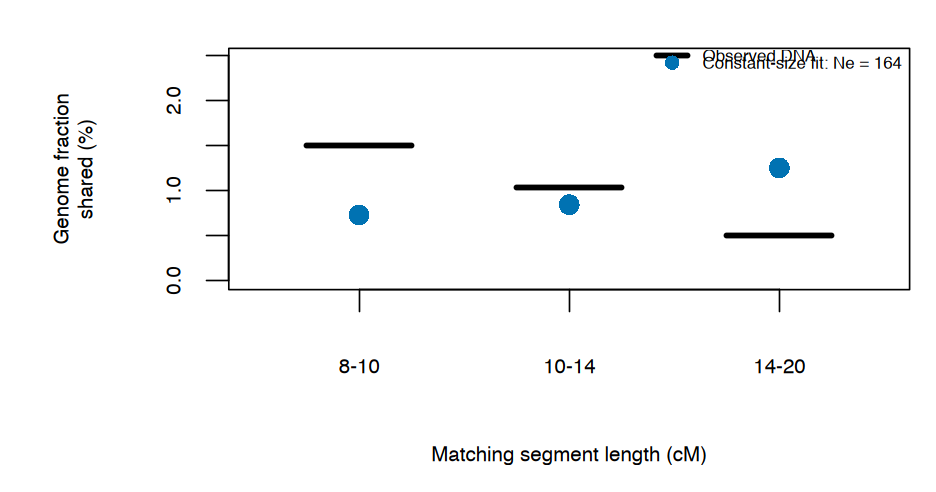

In [11]:
ibd_haplotypes <- ld_haplotypes
frequency <- colMeans(ibd_haplotypes)
common <- frequency >= population_design$ibd_minimum_maf &
          frequency <= 1 - population_design$ibd_minimum_maf
ibd_segments <- detectIbdSegments(ibd_haplotypes[, common, drop = FALSE],
    geneticPositions = observed$markers$genetic_position[common],
    chromosome = observed$markers$chromosome[common],
    wordSize = 1L, minimumCm = population_design$ibd_length_breaks[1L])
chromosome_lengths_cm <- vapply(split(observed$markers$genetic_position,
    observed$markers$chromosome), function(p) 100 * diff(range(p)), numeric(1))
haplotype_pairs <- choose(nrow(ibd_haplotypes), 2L)
ibd_fit <- estimateIbdSize(ibd_segments, haplotype_pairs,
    chromosome_lengths_cm, lengthBreaks = population_design$ibd_length_breaks)
print(ibd_fit$bins, row.names = FALSE)
cat("Constant-size IBD fit:", round(ibd_fit$Ne, 1), "\n")

drawFigure("population_ibd_estimates", function() {
    par(mar = c(4.6, 5.2, 1.1, .6), bg = "white")
    y <- 100 * ibd_fit$bins$fraction
    predicted <- 100 * ibd_fit$predicted
    plot(NA, xlim = c(.5, 3.5), ylim = c(0, max(y, predicted) * 1.65),
        xaxt = "n", xlab = "Matching segment length (cM)",
        ylab = "Genome fraction\nshared (%)")
    axis(1, 1:3, c("8-10", "10-14", "14-20"))
    points(1:3, predicted, col = blue, pch = 16, cex = 1.2)
    segments((1:3)-.25, y, (1:3)+.25, y, lwd = 3.5, col = "black")
    legend("topright", c("Observed DNA", sprintf("Constant-size fit: Ne = %.0f", ibd_fit$Ne)),
        col = c("black", blue), lty = c(1, NA), pch = c(NA,16), lwd = c(3.5, 3), bty = "n", cex = .82)
}, width = 7.8, height = 4.1, pointsize = 22)


The expanded DNA panel gives 937 matches of at least 8 cM and a
constant-size fit of approximately 164. The observed length distribution and the constant-size prediction have
different shapes. The next comparison lets population size vary through time.

In a separate validation replay, about 97.7% of matched length had the same
recorded founder-copy label. Independently shuffling each marker preserved
allele counts and produced no matches of at least 8 cM in that control.
These checks support the chosen matching threshold. They do not establish
perfect segment boundaries or eliminate mutation and chance-matching error.


### Check the constant-size assumption

Change the length threshold and binning while using the same detected segments.
The fitted scalar can change because different lengths weight different
ancestral generations. A changing history also changes the shape of the
length distribution, as the observed-versus-fitted plot shows.


In [12]:
sensitivity_bins <- list(
    "8-10, 10-14, 14+ cM" = c(8,10,14,Inf),
    "8-14, 14+ cM" = c(8,14,Inf),
    "10-14, 14+ cM" = c(10,14,Inf),
    "12-14, 14+ cM" = c(12,14,Inf))
sensitivity_fits <- lapply(sensitivity_bins,function(b)
    estimateIbdSize(ibd_segments,haplotype_pairs,chromosome_lengths_cm,lengthBreaks=b))
print(data.frame(length_bins=names(sensitivity_bins),
    Ne=vapply(sensitivity_fits,`[[`,0,"Ne")),row.names=FALSE,digits=5)


         length_bins     Ne
 8-10, 10-14, 14+ cM 164.14
        8-14, 14+ cM 205.22
       10-14, 14+ cM 234.80
       12-14, 14+ cM 309.05


               method estimate
 Diversity + mutation  73.2294
   LD + recombination 295.1005
          IBD lengths 164.1379


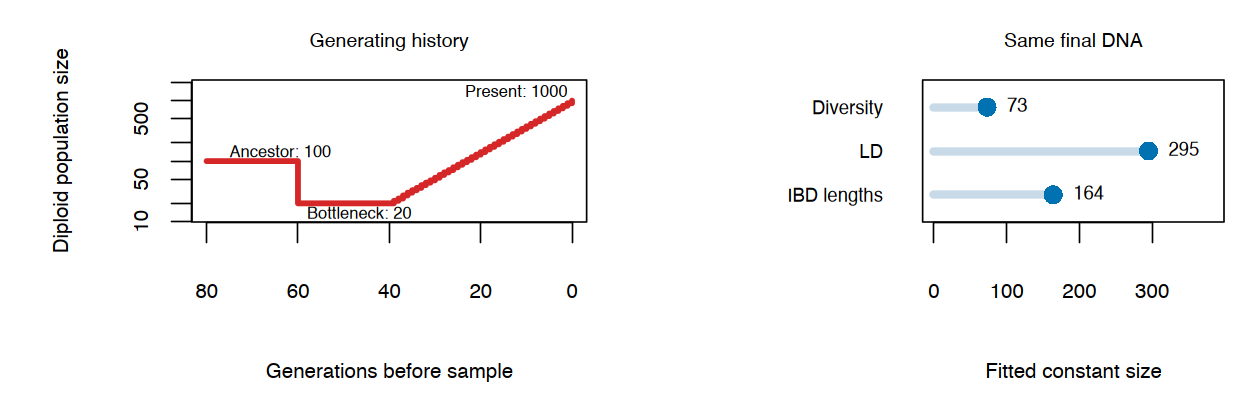

In [13]:
print(data.frame(method = c("Diversity + mutation", "LD + recombination", "IBD lengths"),
    estimate = c(diversity_fit$Ne, ld_fit$Ne, ibd_fit$Ne)), row.names = FALSE, digits = 6)
drawFigure("population_ne_comparison", function() {
    layout(matrix(1:2, nrow = 1), widths = c(1, 1.05))
    par(mar = c(4.5, 4.8, 2.0, .7), bg = "white")
    candidate <- candidate_designs$recent_founding
    schedule <- populationSizeSchedule(candidate, population_design)
    schedule[1L] <- candidate$founder
    age <- rev(seq_along(schedule) - 1L)
    plot(c(80, 60.01, age), c(population_design$ancestral_size,
        population_design$ancestral_size, schedule), type = "s", log = "y",
        xlim = c(80, 0), ylim = c(12, 1800), col = truth_color, lwd = 3.5,
        xlab = "Generations before sample", ylab = "Diploid population size",
        main = "Generating history", cex.main = .95)
    text(75, 145, "Ancestor: 100", adj = 0, cex = .8)
    text(58, 14, "Bottleneck: 20", adj = 0, cex = .8)
    text(1, 1450, "Present: 1000", adj = 1, cex = .8)
    values <- c(diversity_fit$Ne, ld_fit$Ne, ibd_fit$Ne)
    par(mar = c(4.5, 7.7, 2.0, .9))
    plot(NA, xlim = c(0, max(values)*1.3), ylim = c(.5, 3.5), yaxt = "n",
        xlab = "Fitted constant size", ylab = "", main = "Same final DNA", cex.main = .95)
    axis(2, 3:1, c("Diversity", "LD", "IBD lengths"), las = 1, tick = FALSE, cex.axis = .9)
    segments(0, 3:1, values, 3:1, col = "#C8D9E8", lwd = 5)
    points(values, 3:1, pch = 16, col = blue, cex = 1.2)
    text(values, 3:1, sprintf("%.0f", values), pos = 4, cex = .9)
}, width = 10.5, height = 3.35, pointsize = 20)


The same DNA gives different constant-size summaries: diversity 73.2,
LD 295, and IBD lengths 164. Each calculation inverts a different
relationship under a constant-size model. With changing size, the estimators
weight ancestral generations differently and also respond to sampling,
marker selection and approximation error. None identifies one historical date.

The founder event leaves many variants on 40 chromosome copies. During the
40 generations of expansion, new mutations continue to arise. Recorded
population diversity rises from 0.006544 to 0.007288, while the number of
variable sites rises from 1,756 to 13,138. Rare new variants contribute little
to pairwise diversity. Growth reduces drift loss immediately; a new diversity
equilibrium takes much longer.


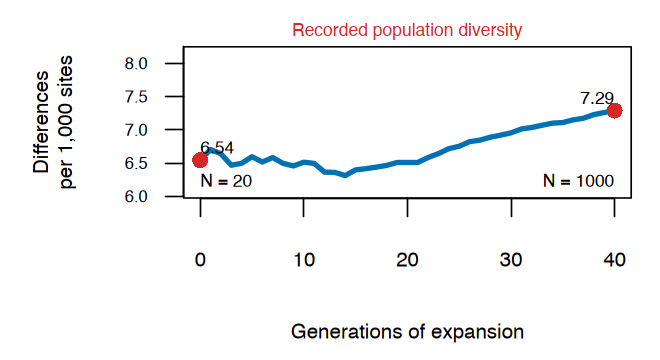

In [14]:
drawFigure("population_diversity_growth", function() {
    record <- simulation$records$generation
    H <- record$heterozygosity * 2 * record$size / (2 * record$size - 1)
    use <- record$generation >= population_design$bottleneck_generations
    time <- record$generation[use] - population_design$bottleneck_generations
    values <- 1000*H[use]
    limits <- range(values)*c(.96,1.12)
    par(mar = c(4.5, 5.1, 1.3, .8), bg = "white")
    plot(time,values,type="l",lwd=3.2,col=blue,
        xlab="Generations of expansion",ylab="Differences\nper 1,000 sites",
        ylim=limits,yaxt="n")
    axis(2,at=pretty(limits,n=4),las=1,cex.axis=.8)
    points(c(0,40),values[c(1,length(values))],pch=16,col=truth_color,cex=1.1)
    text(0,values[1]+.10,sprintf("%.2f",values[1]),adj=c(0,0),cex=.85)
    text(tail(time,1),tail(values,1)+.10,sprintf("%.2f",tail(values,1)),adj=c(1,0),cex=.85)
    text(0,limits[1]+.04*diff(limits),sprintf("N = %d",record$size[which(use)[1]]),adj=c(0,0),cex=.85)
    text(tail(time,1),limits[1]+.04*diff(limits),sprintf("N = %d",tail(record$size,1)),adj=c(1,0),cex=.85)
    mtext("Recorded population diversity",side=3,line=.2,col=truth_color,cex=.85)
},width=5.5,height=3.0,pointsize=18)


## Compare explicit population histories

All candidates begin at 100, end at 1,000, and use the same mutation rate,
map, sequence length and sampling design. The plot shows the 120 generations
before the final sample at time 0.

- The recent founder events occur 60 generations before sampling. Population
  size stays at 20 or 40 until 40 generations before sampling, then expands.
- The older event occurs 100 generations before sampling. Population size
  stays at 20 until 80 generations before sampling, then expands for 80 generations.

These are competing hypotheses for one sample, not additional example
populations. We compare which declared trajectory predicts the sample best;
the comparison does not estimate arbitrary founder numbers or dates.


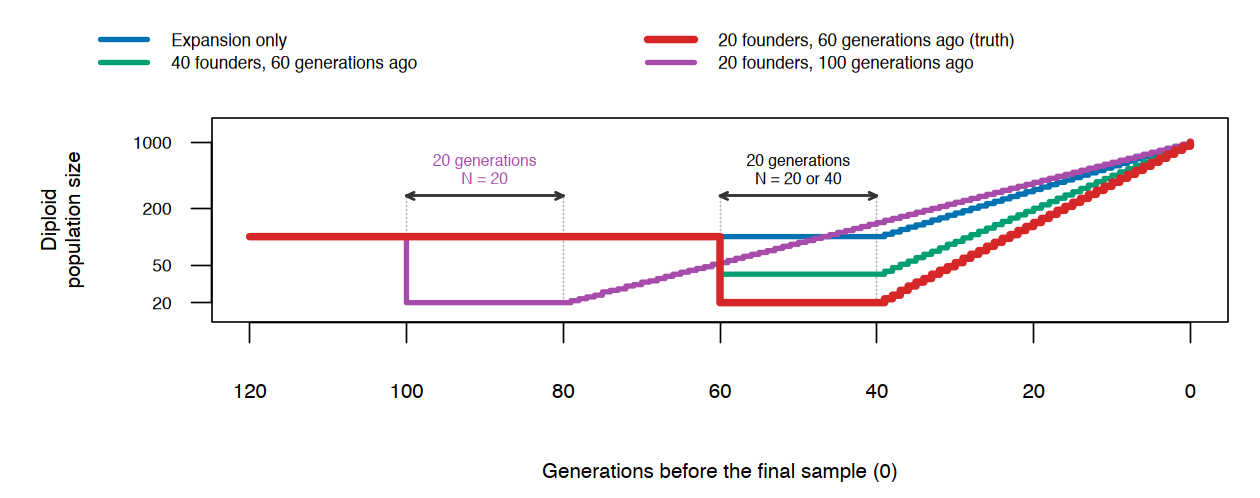

In [15]:
drawFigure("population_candidate_histories", function() {
    historyColors <- c(expansion_only = "#0072B2", shallow_founding = "#009E73",
        recent_founding = "#D62728", older_founding = "#A84CAB")
    lineWidths <- ifelse(names(candidate_designs) == "recent_founding", 4.5, 3.2)
    layout(matrix(1:2, ncol = 1L), heights = c(.85, 3.3))
    par(mar = rep(0, 4), bg = "white")
    plot.new()
    validation_labels <- candidate_labels
    validation_labels["recent_founding"] <- paste0(
        validation_labels["recent_founding"], " (truth)")
    legend("center", validation_labels, col = historyColors[names(candidate_designs)],
           lty = 1, lwd = lineWidths, bty = "n", cex = .83,
           y.intersp = 1.8, ncol = 2)
    par(mar = c(4.4, 5.3, .4, .8))
    plot(NA, xlim = c(120, 0), ylim = c(15, 1500), log = "y",
         xlab = "Generations before the final sample (0)", ylab = "",
         xaxt = "n", yaxt = "n")
    axis(1, at = seq(0, 120, 20))
    axis(2, at = c(20, 50, 200, 1000), labels = c(20, 50, 200, 1000), cex.axis = .85, las = 1)
    mtext("Diploid\npopulation size", side = 2, line = 3.2)
    for (interval in list(c(100, 80), c(60, 40))) {
        segments(interval, 20, interval, 270, col = "#B8B8B8", lty = 3)
        arrows(interval[1], 270, interval[2], 270, code = 3,
               angle = 25, length = .07, lwd = 1.7, col = "#333333")
    }
    text(90, 520, "20 generations\nN = 20", cex = .76, col = historyColors["older_founding"])
    text(50, 520, "20 generations\nN = 20 or 40", cex = .76)
    drawOrder <- c(which(names(candidate_designs) != "recent_founding"),
                   which(names(candidate_designs) == "recent_founding"))
    for (i in drawOrder) {
        candidate <- candidate_designs[[i]]
        schedule <- populationSizeSchedule(candidate, population_design)
        age <- rev(seq_along(schedule) - 1L)
        schedule[1L] <- if (is.null(candidate$founder)) 100L else candidate$founder
        lines(c(120, age[1] + .01, age), c(100, 100, schedule),
              type = "s", lwd = lineWidths[i],
              col = historyColors[names(candidate_designs)[i]], lty = 1)
    }
}, width = 10.5, height = 4.15, pointsize = 20)


Fit with chromosomes 1-6 and reserve chromosomes 7-8 for a predictive check.
For each candidate history, 40 independent forward simulations predict seven
SFS groups, six LD-distance bins and three IBD-length bins. Another 40
simulations per history test whether the comparison identifies their known
histories. These 320 seeds differ from the observation seed.

Dots in the next plots show prediction means. Intervals show the central 90%
of simulated datasets; black horizontal marks show the observed DNA.

### Standardized Euclidean distance

Let $x_b$ be observed summary $b$, and $m_b(\eta)$ its predicted mean under
history $\eta$. Divide each difference by its simulation standard deviation:

$$d(\eta)=\sqrt{\sum_{b=1}^{16}
  \left[\frac{x_b-m_b(\eta)}{s_b}\right]^2}.$$

The common $s_b^2$ is the average of the four within-history simulation
variances. Use the same summaries and scales for every candidate, then choose
the smallest distance. This is a choice of comparison rule; its accuracy is
measured with independent simulations whose generating histories are known.


In [16]:
fit_features <- populationSampleFeatures(observed, population_design, population_design$fitting_chromosomes)
check_features <- populationSampleFeatures(observed, population_design, population_design$checking_chromosomes)
banks <- prediction_data$banks
history_library <- buildHistoryLibrary(
    training = lapply(banks, `[[`, "train_fit"),
    calibration = lapply(banks, `[[`, "cal_fit"))
heldout_library <- buildHistoryLibrary(
    training = lapply(banks, `[[`, "train_check"),
    calibration = lapply(banks, `[[`, "cal_check"))
history_fit <- comparePopulationHistories(fit_features, history_library)
history_check <- comparePopulationHistories(check_features, heldout_library)


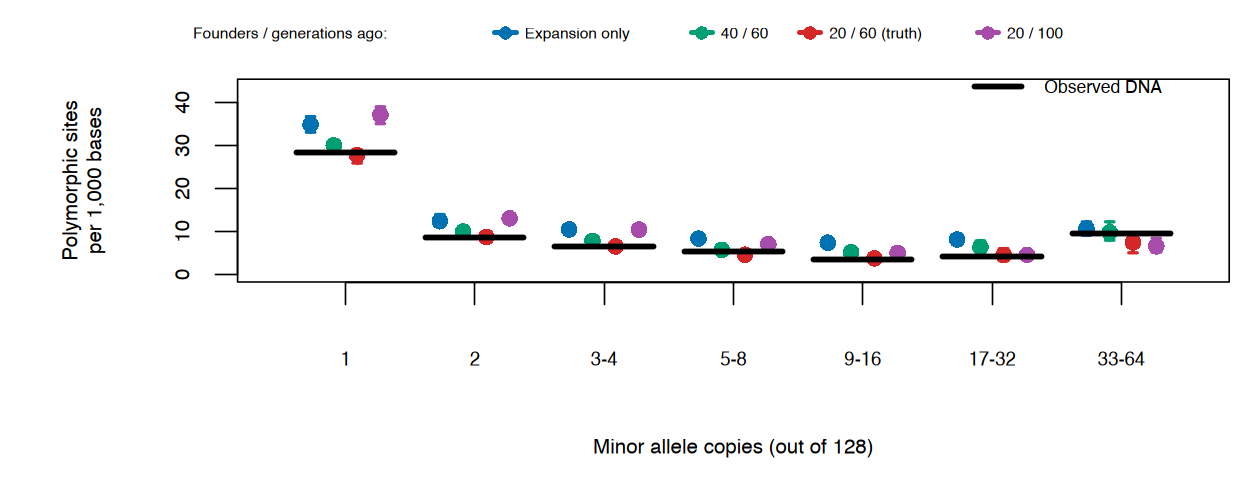

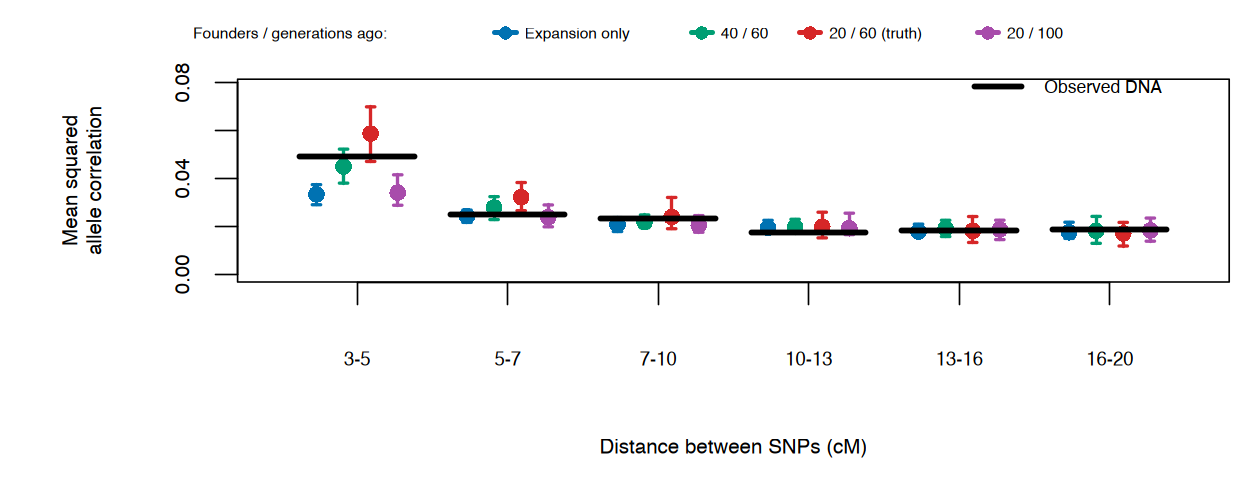

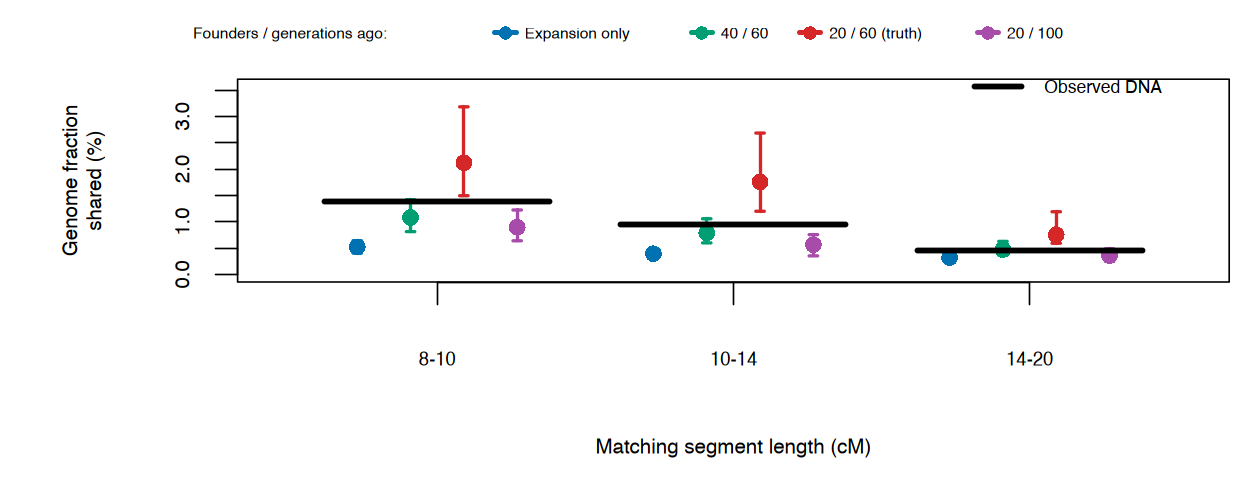

In [17]:
prediction_panels <- list(
    sfs = list(index = grep("^sfs_", names(fit_features)), labels = c("1", "2", "3-4", "5-8", "9-16", "17-32", "33-64"),
        factor = 1000, xlab = "Minor allele copies (out of 128)", ylab = "Polymorphic sites\nper 1,000 bases"),
    ld = list(index = grep("^ld_", names(fit_features)), labels = c("3-5", "5-7", "7-10", "10-13", "13-16", "16-20"),
        factor = 1, xlab = "Distance between SNPs (cM)", ylab = "Mean squared\nallele correlation"),
    ibd = list(index = grep("^ibd_", names(fit_features)), labels = c("8-10", "10-14", "14-20"),
        factor = 100, xlab = "Matching segment length (cM)", ylab = "Genome fraction\nshared (%)"))
drawPredictionPanel <- function(panel) {
        layout(matrix(1:2,ncol=1),heights=c(.55,3.45))
        par(mar=rep(0,4),bg="white");plot.new()
        legend("center", c("Founders / generations ago:", "Expansion only", "40 / 60", "20 / 60 (truth)", "20 / 100"),
            col=c("black",model_colors),lwd=3,pch=c(NA,rep(16,4)),lty=c(NA,rep(1,4)),
            bty="n",ncol=5,text.width=NA,cex=.75,x.intersp=.4,seg.len=1.0,y.intersp=1.0)
        index <- panel$index; multiplier <- panel$factor
        means <- history_library$centers[,index,drop=FALSE]*multiplier
        ranges <- lapply(history_library$training,function(x)
            apply(x[,index,drop=FALSE]*multiplier,2,quantile,c(.05,.95)))
        actual <- fit_features[index]*multiplier
        par(mar=c(4.5,5.4,.3,.7))
        plot(NA,xlim=c(.45,length(index)+.55),ylim=c(0,max(c(actual,unlist(ranges)))*1.12),
            xaxt="n",xlab=panel$xlab,ylab=panel$ylab)
        axis(1,seq_along(index),panel$labels,cex.axis=.9)
        offsets <- seq(-.27,.27,length.out=4)
        for(j in 1:4){
            at<-seq_along(index)+offsets[j];r<-ranges[[j]]
            arrows(at,r[1,],at,r[2,],angle=90,code=3,length=.035,col=model_colors[j],lwd=2)
            points(at,means[j,],pch=16,col=model_colors[j],cex=.95)
        }
        segments(seq_along(index)-.38,actual,seq_along(index)+.38,actual,lwd=3.5,col="black")
        legend("topright", "Observed DNA", col="black", lty=1, lwd=3.5,bty="n",cex=.85)
}
drawFigure("population_history_predictions_sfs",function() drawPredictionPanel(prediction_panels$sfs),
    width=10.5,height=4.0,pointsize=22)
drawFigure("population_history_predictions_ld",function() drawPredictionPanel(prediction_panels$ld),
    width=10.5,height=4.0,pointsize=22)
drawFigure("population_history_predictions_ibd",function() drawPredictionPanel(prediction_panels$ibd),
    width=10.5,height=4.0,pointsize=22)


          history distance
 shallow_founding   5.7323
  recent_founding   5.9100
   older_founding  14.0624
   expansion_only  15.8253


                  selected
generating         expansion_only shallow_founding recent_founding older_founding
  expansion_only               40                0               0              0
  shallow_founding              0               40               0              0
  recent_founding               0                2              38              0
  older_founding                0                0               0             40


          history correct validation_datasets accuracy lower95 upper95
   expansion_only      40                  40     1.00  0.9119  1.0000
 shallow_founding      40                  40     1.00  0.9119  1.0000
  recent_founding      38                  40     0.95  0.8308  0.9939
   older_founding      40                  40     1.00  0.9119  1.0000


Correct histories: 158 of 160 (98.75%)


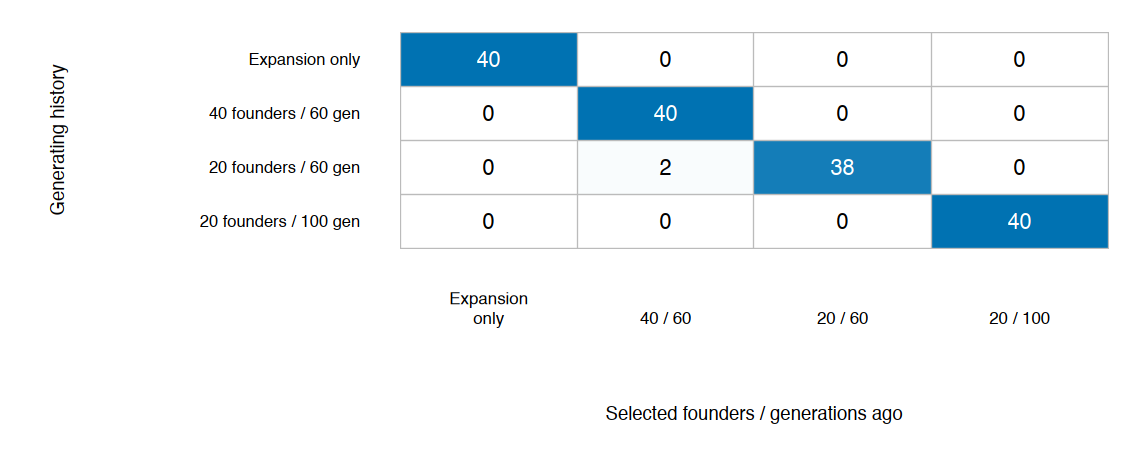

In [18]:
distance_profile <- data.frame(history = history_fit$profile$candidate,
    distance = sqrt(history_fit$profile$discrepancy))
print(distance_profile, row.names = FALSE, digits = 5)

history_ids <- names(history_library$calibration)
validation_true <- rep(history_ids,
    vapply(history_library$calibration, nrow, integer(1)))
validation_selected <- unlist(lapply(history_library$calibration, function(draws)
    apply(draws, 1L, function(x)
        comparePopulationHistories(x, history_library)$selected)), use.names = FALSE)
confusion <- table(
    generating = factor(validation_true, levels = history_ids),
    selected = factor(validation_selected, levels = history_ids))
validation_accuracy <- sum(diag(confusion)) / sum(confusion)
recovery_intervals <- t(vapply(seq_along(history_ids), function(i)
    binom.test(confusion[i,i], sum(confusion[i,]))$conf.int, numeric(2)))
recovery <- data.frame(history = history_ids, correct = diag(confusion),
    validation_datasets = rowSums(confusion),
    accuracy = diag(confusion) / rowSums(confusion),
    lower95 = recovery_intervals[,1], upper95 = recovery_intervals[,2],
    row.names = NULL)
print(confusion)
print(recovery, row.names = FALSE, digits = 4)
cat("Correct histories:", sum(diag(confusion)), "of", sum(confusion),
    sprintf("(%.2f%%)\n", 100 * validation_accuracy))
stopifnot(all(rowSums(confusion) == 40L), sum(confusion) == 160L)

drawFigure("population_history_validation", function() {
    par(mar = c(5.2, 10.0, .8, .8), bg = "white")
    palette <- colorRampPalette(c("white", "#C7E3F3", "#0072B2"))(80)
    image(1:4, 1:4, t(confusion[4:1,]), axes = FALSE, xlab = "", ylab = "",
        xlim = c(.5,4.5), ylim = c(.5,4.5),
        col = palette, breaks = seq(-.5,40.5,length.out = 81))
    abline(h = seq(.5,4.5), v = seq(.5,4.5), col = "#BBBBBB", lwd = .8)
    axis(1, 1:4, c("Expansion\nonly", "40 / 60", "20 / 60", "20 / 100"),
        tick = FALSE, cex.axis = .82)
    axis(2, 4:1, c("Expansion only", "40 founders / 60 gen",
        "20 founders / 60 gen", "20 founders / 100 gen"),
        tick = FALSE, las = 1, cex.axis = .8)
    mtext("Selected founders / generations ago", 1, line = 3.4, cex = .9)
    mtext("Generating history", 2, line = 8.3, cex = .9)
    for(i in 1:4) for(j in 1:4) text(j,5-i,confusion[i,j],font=2,
        col=if(confusion[i,j] >= 20) "white" else "black",cex=1.05)
}, width = 9.5, height = 3.8, pointsize = 20)


Among the 160 independent validation populations, the rule identifies
158 generating histories correctly (98.75%). Two of the 40 datasets generated
with 20 founders are assigned to the 40-founder history. The per-history
binomial intervals show the uncertainty from using 40 validation datasets.
These rates apply to these four specified histories and this observation design.

The classroom DNA is close to that same boundary: its distances are 5.73 for
40 founders and 5.91 for 20 founders. Both candidates go forward to the reserved
chromosomes. A distance measures closeness to a predicted mean; the validation
counts measure how often this rule identifies a generating history.


        candidate distance
 shallow_founding   6.7837
  recent_founding   4.0877


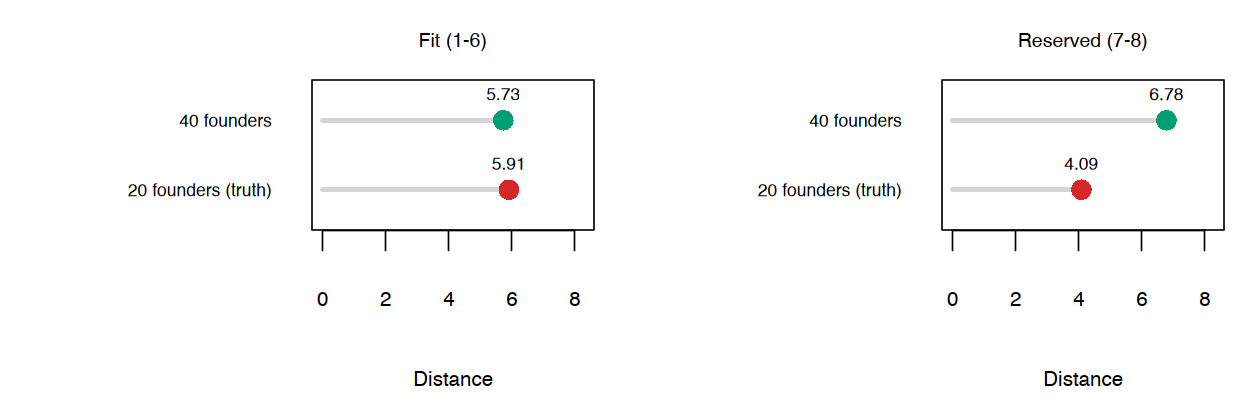

In [19]:
closest_history <- history_fit$selected
leading_histories <- head(history_fit$profile$candidate, 2L)
leading_checks <- history_check$profile[
    match(leading_histories, history_check$profile$candidate), , drop = FALSE]
leading_checks$distance <- sqrt(leading_checks$discrepancy)
print(leading_checks[c("candidate", "distance")], row.names = FALSE, digits = 5)
fit_distances <- sqrt(history_fit$profile$discrepancy[
    match(leading_histories, history_fit$profile$candidate)])
reserved_distances <- leading_checks$distance

drawFigure("population_history_check", function() {
    layout(matrix(1:2, nrow = 1))
    labels <- c("40 founders", "20 founders (truth)")
    values <- list(fit_distances, reserved_distances)
    titles <- c("Fit (1-6)", "Reserved (7-8)")
    limit <- max(unlist(values)) * 1.22
    for(k in 1:2) {
        par(mar = c(4.3,7.8,2.0,.9), bg = "white")
        plot(NA, xlim = c(0,limit), ylim = c(.5,2.5), yaxt = "n",
            xlab = "Distance", ylab = "",
            main = titles[k], cex.main = .95)
        axis(2, 2:1, labels, las = 1, tick = FALSE, cex.axis = .85)
        segments(0, 2:1, values[[k]], 2:1, col = "#D5D5D5", lwd = 3)
        points(values[[k]], 2:1, pch = 16, col = model_colors[leading_histories], cex = 1.3)
        text(values[[k]], 2:1, sprintf("%.2f",values[[k]]), pos = 3, cex = .85)
    }
}, width = 10.5, height = 3.35, pointsize = 20)


The means predicted by 40 founders are slightly closer on chromosomes 1-6.
The reserved chromosomes are closer to the 20-founder prediction (4.09 versus
6.78). These are comparisons of this one sample with fixed candidate histories.
The independent validation above measures the rule's identification accuracy.

The simulations preserve the shared pedigree across chromosomes. Reserved
chromosomes provide additional genetic information within that pedigree.


## Read the final sample's results together

The same DNA gives constant-size summaries of about 73 from diversity,
295 from LD and 164 from IBD lengths. These summarize different features
of a history whose size changed.

The candidate comparison uses standardized Euclidean distance. In independent
validation, it identifies 158 of 160 generating histories; two 20-founder
populations are assigned to 40 founders. Those are the two close candidates
for the classroom sample as well. Reserved chromosomes are closer to the
20-founder prediction. The validation rate describes recovery among the
four specified histories under the chosen rates, map and observation design.


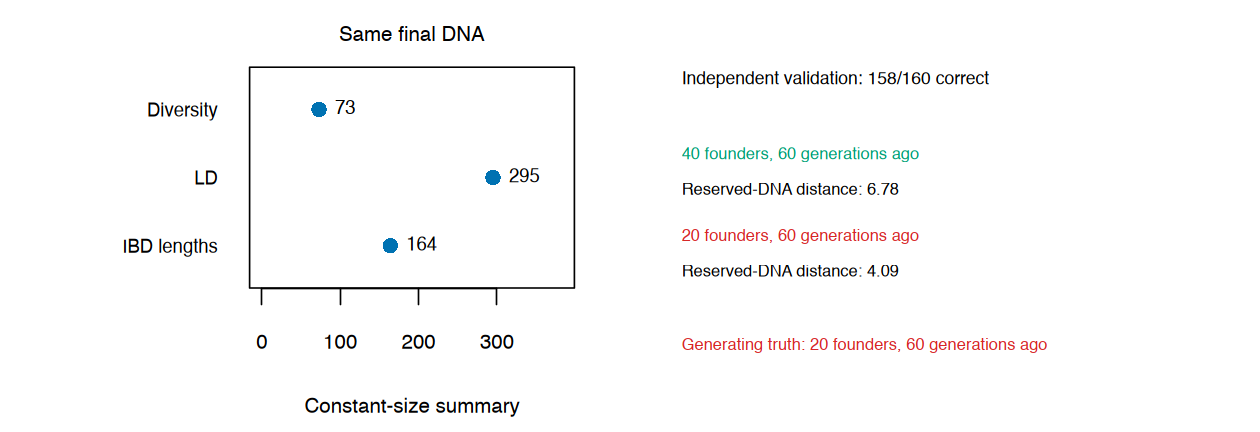

In [20]:
comparison_validation <- list(
    diversity_estimate = unname(diversity_fit$Ne),
    finite_state_estimate = unname(finite_state_fit$Ne),
    ld_estimate = unname(ld_fit$Ne),
    ibd_estimate = unname(ibd_fit$Ne),
    current_census = population_design$present_size,
    selected_history = history_fit$selected,
    closest_reserved_distance = unname(reserved_distances[1L]),
    validation_accuracy = unname(validation_accuracy))

package_result <- populationHistoryExample(observed, calibration, prediction_data)
stopifnot(identical(diversity_fit, package_result$diversity_fit),
          identical(finite_state_fit, package_result$finite_state_fit),
          identical(ld_fit, package_result$ld_fit),
          identical(ibd_fit, package_result$ibd_fit),
          identical(history_fit, package_result$history_fit),
          identical(history_check, package_result$history_check))

drawFigure("p7_common_sample_validation", function() {
    layout(matrix(1:2,nrow=1),widths=c(1,1.1))
    par(mar=c(4.5,7.8,2.1,.8),bg="white")
    values<-c(diversity_fit$Ne,ld_fit$Ne,ibd_fit$Ne)
    plot(NA,xlim=c(0,max(values)*1.3),ylim=c(.5,3.5),yaxt="n",xlab="Constant-size summary",ylab="")
    axis(2,3:1,c("Diversity","LD","IBD lengths"),las=1,tick=FALSE,cex.axis=.9)
    points(values,3:1,pch=16,col=blue,cex=1.2)
    text(values,3:1,sprintf("%.0f",values),pos=4,cex=.9)
    title("Same final DNA",cex.main=1)
    par(mar=c(1,1,1,1));plot.new()
    text(.05,.90,sprintf("Independent validation: %d/%d correct",sum(diag(confusion)),sum(confusion)),
        adj=0,font=2,cex=.85)
    for(j in seq_along(leading_histories)){
        id<-leading_histories[j];y<-.68-(j-1)*.24
        text(.05,y,candidate_labels[id],adj=0,col=model_colors[id],cex=.8)
        text(.05,y-.10,sprintf("Reserved-DNA distance: %.2f",reserved_distances[j]),adj=0,cex=.8)
    }
    text(.05,.12,"Generating truth: 20 founders, 60 generations ago",adj=0,col=truth_color,cex=.8)
},width=10.5,height=3.6,pointsize=16)


## Rebuild the cache

The observations and all prediction/calibration replicates use hpgR's R
functions with the recorded design and seeds. From the package source:

```r
system2("Rscript", c("tools/rebuild_population_cache.R", "/path/to/cache", "4"))
```

The generated RDS files contain the inputs embedded in this notebook.


## Sources

[Pritchard, Sections 2.1-2.3](https://web.stanford.edu/group/pritchardlab/HGBook.html);
Peng et al. (2012), *Forward-Time Population Genetics Simulations*;
[Hill (1981)](https://www.cambridge.org/core/journals/genetics-research/article/estimation-of-effective-population-size-from-data-on-linkage-disequilibrium1/AA65A3B2E03EB5590444B886935D325E);
*Handbook of Statistical Genomics*, Section 16.2.2;
[Carmi et al. (2014)](https://www.nature.com/articles/ncomms5835);
[Browning and Browning (2015)](https://pmc.ncbi.nlm.nih.gov/articles/PMC4564943/).

IBD matching and length expectations are translated from Daniel Nachun's
supplied demographyTools. Simulation and inference interfaces are documented
in hpgR.

[Beaumont et al. (2002), simulation-based comparison of standardized summaries](https://pmc.ncbi.nlm.nih.gov/articles/PMC1462356/);
[Csilléry et al., independent model-recovery checks in the abc documentation](https://search.r-project.org/CRAN/refmans/abc/html/cv4postpr.html).
Here candidates are compared by distance to their simulated means; no ABC
posterior is computed.
